# Member A — Cross-Event Flood Mapping
## Reproducible evaluation and Amphan inference

This notebook reproduces the **final checkpoint-based evaluation and Amphan analysis** from the shared project workspace. It uses the supplied trained checkpoint; it does **not** retrain the U-Net.

### Before running
1. Add the shared `Member_A` Google Drive folder as a shortcut in **My Drive**.
2. Run the setup cells to mount Drive and check the workspace.
3. Run the final dataset and dataloader cells, then initialize the model.
4. Run test evaluation and Amphan analysis in order.

**Do not use this notebook to retrain the model.** The full training history and the final training code are retained in `Member_A_Final.ipynb`. The final training cell is intentionally omitted here to prevent accidental retraining or overwriting the shared checkpoint.

### Shared workspace expected by this notebook
`/content/drive/MyDrive/Member_A/07_Reproduction_Workspace`

The notebook expects the copied clean split CSVs, clipped normalization statistics, raw Sentinel-1 images and labels, the final checkpoint, and the pre/post Amphan input TIFFs to be present in that workspace.

### Reproduction scope
- Rebuilds the final datasets and dataloaders from the shared prepared files.
- Loads the saved final U-Net checkpoint for unseen-test evaluation.
- Recreates per-image and visual error analysis.
- Recreates Amphan pre/post inference, weighted tile blending, transition clusters, and threshold sensitivity.

The larger `Amphan_Post_Event.tif` export is retained in the workspace for the earlier coverage/alignment audit, but is not required by the final pre/post inference cells in this notebook.

The historical exploratory experiments and one-time dataset-download / handover cells are excluded. The original notebook remains the complete experiment archive.


## 1. Environment and Google Drive setup

In [1]:

# Our first environment check

import sys
import platform

print("PROJECT: Cross-Event Flood Mapping")
print("-----------------------------------")

print("Python version:", sys.version)
print("Operating system:", platform.system())

print("Environment setup started successfully!")


PROJECT: Cross-Event Flood Mapping
-----------------------------------
Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Operating system: Linux
Environment setup started successfully!


In [2]:

# ==========================================
# STEP 1: CHECK PYTORCH AND GPU
# ==========================================

import torch

print("PyTorch version:", torch.__version__)

print("--------------------------------")

if torch.cuda.is_available():

    print("SUCCESS: GPU is available!")

    print("GPU name:", torch.cuda.get_device_name(0))

    gpu_memory = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    print("GPU memory:", round(gpu_memory, 2), "GB")

else:

    print("GPU is NOT available.")
    print("Please check your Colab runtime settings.")


PyTorch version: 2.14.1+cpu
--------------------------------
GPU is NOT available.
Please check your Colab runtime settings.


In [3]:

# ==========================================
# STEP 2: CONNECT GOOGLE DRIVE
# ==========================================

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive connected successfully!")


Mounted at /content/drive
Google Drive connected successfully!


In [4]:

# ==========================================
# STEP 3: CREATE PROJECT FOLDERS
# ==========================================

import os

# Main project directory
PROJECT_DIR = "/content/drive/MyDrive/Member_A/07_Reproduction_Workspace"

# Folders required for our project
folders = [
    "data/raw",
    "data/processed",
    "data/splits",
    "checkpoints",
    "logs",
    "results",
    "notebooks"
]

# Create all folders
for folder in folders:

    path = os.path.join(PROJECT_DIR, folder)

    os.makedirs(path, exist_ok=True)

    print("Created:", folder)

print("\nPROJECT WORKSPACE CREATED SUCCESSFULLY!")


Created: data/raw
Created: data/processed
Created: data/splits
Created: checkpoints
Created: logs
Created: results
Created: notebooks

PROJECT WORKSPACE CREATED SUCCESSFULLY!


In [5]:

# Verify project workspace

print("Project directory exists:",
      os.path.exists(PROJECT_DIR))

print("\nProject folders:")

for item in sorted(os.listdir(PROJECT_DIR)):
    print(" -", item)


Project directory exists: True

Project folders:
 - checkpoints
 - data
 - logs
 - notebooks
 - results


In [6]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Member_A/07_Reproduction_Workspace"
)

required_paths = [
    PROJECT_DIR / "data/raw/S1Hand",
    PROJECT_DIR / "data/LabelHand",
    PROJECT_DIR / "data/processed/clean_splits/train_clean.csv",
    PROJECT_DIR / "data/processed/clean_splits/valid_clean.csv",
    PROJECT_DIR / "data/processed/clean_splits/test_evaluable.csv",
    PROJECT_DIR / "data/processed/normalization_stats_clipped.json",
    PROJECT_DIR / "checkpoints/best_unet_resnet34_final_iou.pth",
    PROJECT_DIR / "data/amphan_inputs/test_pre_event_s1.tif",
    PROJECT_DIR / "data/amphan_inputs/test_post_event_s1.tif",
]

missing = [str(p) for p in required_paths if not p.exists()]

print("SHARED WORKSPACE PREFLIGHT")
print("--------------------------------")
print("Workspace:", PROJECT_DIR)
print("Required paths checked:", len(required_paths))

if missing:
    print("\nMISSING:")
    for item in missing:
        print("-", item)
    raise FileNotFoundError(
        "Required shared files are missing. Check Drive shortcut and transfer."
    )

print("All required inputs and checkpoint are available.")


SHARED WORKSPACE PREFLIGHT
--------------------------------
Workspace: /content/drive/MyDrive/Member_A/07_Reproduction_Workspace
Required paths checked: 9
All required inputs and checkpoint are available.


## 2. Install and verify the model library

In [7]:

%pip install -q segmentation-models-pytorch==0.6.0


In [8]:

# Check U-Net library installation

import segmentation_models_pytorch as smp

print("Library installed successfully!")
print("Version:", smp.__version__)


Library installed successfully!
Version: 0.6.0


## 3. Final dataset and preprocessing

In [9]:

# ==========================================
# MEMBER A: UPDATED FLOOD DATASET
# CLIPPING + NORMALIZATION + NO-DATA MASKING
# ==========================================

import json
import numpy as np
import pandas as pd
import torch
import rasterio

from pathlib import Path
from torch.utils.data import Dataset


# 1. PROJECT PATHS

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Member_A/07_Reproduction_Workspace"
)

S1_DIR = PROJECT_DIR / "data/raw/S1Hand"
LABEL_DIR = PROJECT_DIR / "data/LabelHand"

CLEAN_DIR = PROJECT_DIR / "data/processed/clean_splits"


# 2. LOAD FINAL PREPROCESSING STATISTICS

with open(
    PROJECT_DIR / "data/processed/normalization_stats_clipped.json",
    "r"
) as f:
    stats = json.load(f)

MEAN = np.array(stats["mean"], dtype=np.float32)
STD = np.array(stats["std"], dtype=np.float32)

CLIP_MIN = np.array(stats["clip_min"], dtype=np.float32)
CLIP_MAX = np.array(stats["clip_max"], dtype=np.float32)

assert np.all(STD > 0)
assert np.all(CLIP_MIN < CLIP_MAX)


# 3. LOAD CLEANED TRAINING DATA

train_df = pd.read_csv(
    CLEAN_DIR / "train_clean.csv",
    dtype=str
)


# 4. DEFINE UPDATED DATASET

class FloodDatasetClipped(Dataset):

    def __init__(self, dataframe):

        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = S1_DIR / row["satellite_image"].strip()
        label_path = LABEL_DIR / row["flood_label"].strip()


        # READ SENTINEL-1 IMAGE

        with rasterio.open(image_path) as src:

            image = src.read().astype(np.float32)
            nodata = src.nodata

        if image.ndim != 3 or image.shape[0] != 2:
            raise ValueError(
                f"Expected 2 SAR bands: {image_path.name}"
            )


        # IDENTIFY VALID SAR PIXELS

        valid_sar = np.isfinite(image).all(axis=0)

        if nodata is not None and np.isfinite(nodata):

            valid_sar &= np.all(
                image != nodata,
                axis=0
            )


        # READ FLOOD LABEL

        with rasterio.open(label_path) as src:

            label = src.read(1)

        if label.shape != image.shape[1:]:
            raise ValueError(
                f"Image-label shape mismatch: {image_path.name}"
            )


        # VALID LABELS ARE 0 (NON-WATER) OR 1 (WATER)

        valid_labels = np.isin(label, [0, 1])

        valid_mask = valid_sar & valid_labels


        # CLIP VV AND VH BEFORE NORMALIZATION

        image = np.clip(
            image,
            CLIP_MIN[:, None, None],
            CLIP_MAX[:, None, None]
        )


        # NORMALIZE USING TRAINING STATISTICS

        image = (
            image - MEAN[:, None, None]
        ) / STD[:, None, None]


        # REPLACE INVALID SAR PIXELS WITH ZERO

        image[:, ~valid_sar] = 0.0


        # CREATE BINARY FLOOD TARGET

        target = np.where(
            valid_mask,
            label == 1,
            False
        ).astype(np.float32)


        # CONVERT TO PYTORCH TENSORS

        image = torch.from_numpy(
            np.ascontiguousarray(image)
        )

        target = torch.from_numpy(
            np.ascontiguousarray(target[None])
        )

        valid_mask = torch.from_numpy(
            np.ascontiguousarray(valid_mask[None])
        )

        return image, target, valid_mask


# 5. CREATE UPDATED TRAINING DATASET

clipped_train_dataset = FloodDatasetClipped(train_df)


# 6. TEST ONE SAMPLE

image, target, mask = clipped_train_dataset[0]

print("UPDATED DATASET TEST")
print("--------------------------------")

print("Training images:", len(clipped_train_dataset))

print("Image shape:", image.shape)
print("Target shape:", target.shape)
print("Mask shape:", mask.shape)

print("Image dtype:", image.dtype)
print("Target dtype:", target.dtype)

print("Valid pixels:", mask.sum().item())

print(
    "Unique target values:",
    torch.unique(target[mask]).tolist()
)

print(
    "Image contains only finite values:",
    torch.isfinite(image).all().item()
)

print("\nUPDATED DATASET WORKING!")


UPDATED DATASET TEST
--------------------------------
Training images: 251
Image shape: torch.Size([2, 512, 512])
Target shape: torch.Size([1, 512, 512])
Mask shape: torch.Size([1, 512, 512])
Image dtype: torch.float32
Target dtype: torch.float32
Valid pixels: 259269
Unique target values: [0.0, 1.0]
Image contains only finite values: True

UPDATED DATASET WORKING!


In [10]:

# ==========================================
# MEMBER A: DATA AUGMENTATION
# ==========================================

import torch
from torch.utils.data import Dataset


class FloodDatasetAugmented(FloodDatasetClipped):

    def __init__(
        self,
        dataframe,
        augment=False,
        crop_size=256
    ):

        super().__init__(dataframe)

        self.augment = augment
        self.crop_size = crop_size


    def __getitem__(self, index):

        # Load clipped and normalized data
        image, target, valid_mask = super().__getitem__(index)

        if not self.augment:
            return image, target, valid_mask

        # Random 256 x 256 crop
        _, height, width = image.shape

        if height < self.crop_size or width < self.crop_size:
            raise ValueError("Image smaller than crop size")

        top = torch.randint(
            0, height - self.crop_size + 1, (1,)
        ).item()

        left = torch.randint(
            0, width - self.crop_size + 1, (1,)
        ).item()

        image = image[
            :, top:top+self.crop_size,
            left:left+self.crop_size
        ]

        target = target[
            :, top:top+self.crop_size,
            left:left+self.crop_size
        ]

        valid_mask = valid_mask[
            :, top:top+self.crop_size,
            left:left+self.crop_size
        ]

        # Horizontal flip
        if torch.rand(1).item() < 0.5:

            image = torch.flip(image, dims=[2])
            target = torch.flip(target, dims=[2])
            valid_mask = torch.flip(valid_mask, dims=[2])

        # Vertical flip
        if torch.rand(1).item() < 0.5:

            image = torch.flip(image, dims=[1])
            target = torch.flip(target, dims=[1])
            valid_mask = torch.flip(valid_mask, dims=[1])

        # Random rotation: 0, 90, 180 or 270 degrees
        k = torch.randint(0, 4, (1,)).item()

        image = torch.rot90(image, k, dims=[1, 2])
        target = torch.rot90(target, k, dims=[1, 2])
        valid_mask = torch.rot90(valid_mask, k, dims=[1, 2])

        return image, target, valid_mask


# ==========================================
# TEST AUGMENTATION
# ==========================================

aug_train_dataset = FloodDatasetAugmented(
    train_df,
    augment=True
)

image, target, mask = aug_train_dataset[0]

print("AUGMENTATION TEST")
print("--------------------------------")

print("Training images:", len(aug_train_dataset))
print("Image shape:", image.shape)
print("Target shape:", target.shape)
print("Mask shape:", mask.shape)

print("Valid pixels:", mask.sum().item())

print(
    "Image finite:",
    torch.isfinite(image).all().item()
)

print(
    "Target values:",
    torch.unique(target[mask]).tolist()
)

print("\nDATA AUGMENTATION WORKING!")


AUGMENTATION TEST
--------------------------------
Training images: 251
Image shape: torch.Size([2, 256, 256])
Target shape: torch.Size([1, 256, 256])
Mask shape: torch.Size([1, 256, 256])
Valid pixels: 65536
Image finite: True
Target values: [0.0, 1.0]

DATA AUGMENTATION WORKING!


In [11]:

# ==========================================
# MEMBER A: AUGMENTATION QUALITY AUDIT
# ==========================================

import numpy as np
import torch

N_SAMPLES = 128

rng = np.random.default_rng(42)
torch.manual_seed(42)

indices = rng.integers(
    0,
    len(aug_train_dataset),
    size=N_SAMPLES
)

water_crops = 0
empty_water_crops = 0

total_valid = 0
total_water = 0

for idx in indices:

    image, target, mask = aug_train_dataset[int(idx)]

    valid = mask.bool()

    valid_count = int(valid.sum().item())

    water_count = int(
        ((target > 0.5) & valid).sum().item()
    )

    total_valid += valid_count
    total_water += water_count

    if water_count > 0:
        water_crops += 1
    else:
        empty_water_crops += 1

print("AUGMENTATION QUALITY AUDIT")
print("--------------------------------")

print("Crops examined:", N_SAMPLES)
print("Crops containing water:", water_crops)
print("Crops without water:", empty_water_crops)

print(
    "Water-containing crop percentage:",
    round(100 * water_crops / N_SAMPLES, 2), "%"
)

print(
    "Overall water pixel percentage:",
    round(100 * total_water / max(total_valid, 1), 4), "%"
)

print("\nAUGMENTATION AUDIT COMPLETED!")


AUGMENTATION QUALITY AUDIT
--------------------------------
Crops examined: 128
Crops containing water: 100
Crops without water: 28
Water-containing crop percentage: 78.12 %
Overall water pixel percentage: 9.9322 %

AUGMENTATION AUDIT COMPLETED!


In [14]:
# FIX: Define device before creating DataLoaders

import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device initialized:", device)
print("GPU available:", torch.cuda.is_available())

Device initialized: cpu
GPU available: False


In [15]:

# ==========================================
# MEMBER A: FINAL DATASET AND DATALOADERS
# ==========================================

import pandas as pd
from torch.utils.data import DataLoader

# 1. LOAD CLEANED CSV FILES

CLEAN_DIR = PROJECT_DIR / "data/processed/clean_splits"

train_df = pd.read_csv(
    CLEAN_DIR / "train_clean.csv",
    dtype=str
)

valid_df = pd.read_csv(
    CLEAN_DIR / "valid_clean.csv",
    dtype=str
)

# Use the 88-image evaluable test split
test_df = pd.read_csv(
    CLEAN_DIR / "test_evaluable.csv",
    dtype=str
)


# 2. CREATE DATASETS

train_dataset = FloodDatasetAugmented(
    train_df,
    augment=True,
    crop_size=256
)

valid_dataset = FloodDatasetAugmented(
    valid_df,
    augment=False
)

test_dataset = FloodDatasetAugmented(
    test_df,
    augment=False
)


# 3. CREATE DATALOADERS

TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)


# 4. TEST TRAINING BATCH

images, labels, masks = next(iter(train_loader))

print("TRAINING BATCH")
print("--------------------------------")

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Masks:", masks.shape)

print("Valid pixels:", masks.sum().item())

print(
    "Unique labels:",
    torch.unique(labels[masks.bool()]).tolist()
)

print(
    "Finite images:",
    torch.isfinite(images).all().item()
)


# 5. TEST VALIDATION BATCH

val_images, val_labels, val_masks = next(iter(valid_loader))

print("\nVALIDATION BATCH")
print("--------------------------------")

print("Images:", val_images.shape)
print("Labels:", val_labels.shape)
print("Masks:", val_masks.shape)


# 6. TEST TESTING BATCH

test_images, test_labels, test_masks = next(iter(test_loader))

print("\nTEST BATCH")
print("--------------------------------")

print("Images:", test_images.shape)
print("Labels:", test_labels.shape)
print("Masks:", test_masks.shape)


# 7. FINAL SUMMARY

print("\nDATASET SUMMARY")
print("--------------------------------")

print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Testing images:", len(test_dataset))

print("Training batches:", len(train_loader))
print("Validation batches:", len(valid_loader))
print("Testing batches:", len(test_loader))

print("Training batch size:", TRAIN_BATCH_SIZE)
print("Evaluation batch size:", EVAL_BATCH_SIZE)

print("\nFINAL DATALOADERS CREATED!")


TRAINING BATCH
--------------------------------
Images: torch.Size([16, 2, 256, 256])
Labels: torch.Size([16, 1, 256, 256])
Masks: torch.Size([16, 1, 256, 256])
Valid pixels: 984339
Unique labels: [0.0, 1.0]
Finite images: True

VALIDATION BATCH
--------------------------------
Images: torch.Size([2, 2, 512, 512])
Labels: torch.Size([2, 1, 512, 512])
Masks: torch.Size([2, 1, 512, 512])

TEST BATCH
--------------------------------
Images: torch.Size([2, 2, 512, 512])
Labels: torch.Size([2, 1, 512, 512])
Masks: torch.Size([2, 1, 512, 512])

DATASET SUMMARY
--------------------------------
Training images: 251
Validation images: 86
Testing images: 88
Training batches: 16
Validation batches: 43
Testing batches: 44
Training batch size: 16
Evaluation batch size: 2

FINAL DATALOADERS CREATED!


In [16]:

# ==========================================
# MEMBER A: COMPLETE DATASET INTEGRITY AUDIT
# ==========================================

splits = {
    "Training": train_df,
    "Validation": valid_df,
    "Testing": test_df
}

for split_name, dataframe in splits.items():

    dataset = FloodDatasetClipped(dataframe)

    empty_images = 0
    water_images = 0
    nonwater_images = 0

    total_valid = 0
    total_water = 0

    print(f"\nAUDITING {split_name.upper()}...")

    for i in range(len(dataset)):

        image, target, mask = dataset[i]

        valid = mask.bool()

        valid_count = int(valid.sum().item())

        water_count = int(
            ((target > 0.5) & valid).sum().item()
        )

        total_valid += valid_count
        total_water += water_count

        if valid_count == 0:
            empty_images += 1
        elif water_count > 0:
            water_images += 1
        else:
            nonwater_images += 1

        if not torch.isfinite(image).all():
            raise ValueError(
                f"Non-finite image in {split_name}: {i}"
            )

    water_percentage = (
        100 * total_water / max(total_valid, 1)
    )

    print("--------------------------------")
    print("Total images:", len(dataset))
    print("Zero-valid-pixel images:", empty_images)
    print("Images containing water:", water_images)
    print("Images without water:", nonwater_images)
    print("Total valid pixels:", f"{total_valid:,}")
    print("Total water pixels:", f"{total_water:,}")
    print("Water percentage:", round(water_percentage, 4), "%")

print("\nCOMPLETE DATASET AUDIT FINISHED!")



AUDITING TRAINING...
--------------------------------
Total images: 251
Zero-valid-pixel images: 0
Images containing water: 219
Images without water: 32
Total valid pixels: 57,279,257
Total water pixels: 5,446,678
Water percentage: 9.509 %

AUDITING VALIDATION...
--------------------------------
Total images: 86
Zero-valid-pixel images: 0
Images containing water: 77
Images without water: 9
Total valid pixels: 20,274,154
Total water pixels: 2,231,206
Water percentage: 11.0052 %

AUDITING TESTING...
--------------------------------
Total images: 88
Zero-valid-pixel images: 0
Images containing water: 82
Images without water: 6
Total valid pixels: 20,443,959
Total water pixels: 2,515,008
Water percentage: 12.302 %

COMPLETE DATASET AUDIT FINISHED!


## 4. Initialize the model and locate the saved checkpoint

In [17]:
# ==========================================
# MEMBER A: LOAD FINAL MODEL ARCHITECTURE
# CHECKPOINT-BASED EVALUATION (NO TRAINING)
# ==========================================

import torch
import segmentation_models_pytorch as smp

torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# The trained checkpoint contains the complete model weights.
# ImageNet encoder download is therefore unnecessary here.
final_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=2,
    classes=1,
    activation=None
).to(device)

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
LOG_DIR = PROJECT_DIR / "logs"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

FINAL_BEST_PATH = (
    CHECKPOINT_DIR / "best_unet_resnet34_final_iou.pth"
)

FINAL_LATEST_PATH = (
    CHECKPOINT_DIR / "latest_unet_resnet34_final_iou.pth"
)

FINAL_HISTORY_PATH = (
    LOG_DIR / "training_history_final_iou.csv"
)

if not FINAL_BEST_PATH.is_file():
    raise FileNotFoundError(
        f"Final trained checkpoint is missing: {FINAL_BEST_PATH}"
    )

print("FINAL MODEL ARCHITECTURE INITIALIZED")
print("--------------------------------")
print("Architecture: U-Net")
print("Encoder: ResNet34")
print("Input channels: 2 (VV + VH)")
print("Output channels: 1")
print("Device:", device)
print("Trainable parameters:", f"{sum(p.numel() for p in final_model.parameters()):,}")
print("Final checkpoint:", FINAL_BEST_PATH)
print("\nREADY TO LOAD THE SAVED CHECKPOINT!")


FINAL MODEL ARCHITECTURE INITIALIZED
--------------------------------
Architecture: U-Net
Encoder: ResNet34
Input channels: 2 (VV + VH)
Output channels: 1
Device: cpu
Trainable parameters: 24,433,233
Final checkpoint: /content/drive/MyDrive/Member_A/07_Reproduction_Workspace/checkpoints/best_unet_resnet34_final_iou.pth

READY TO LOAD THE SAVED CHECKPOINT!


## 5. Unseen test evaluation and error analysis

In [18]:

# ==========================================================
# MEMBER A: FINAL UNSEEN TEST EVALUATION
# ==========================================================

import torch
import numpy as np
import pandas as pd
import json

from tqdm.auto import tqdm


# 1. LOAD BEST CHECKPOINT

checkpoint = torch.load(
    FINAL_BEST_PATH,
    map_location=device,
    weights_only=False
)

final_model.load_state_dict(
    checkpoint["model_state_dict"]
)

final_model.eval()

TEST_THRESHOLD = float(
    checkpoint.get("prediction_threshold", 0.5)
)

print("BEST FINAL CHECKPOINT LOADED")
print("Best epoch:", checkpoint["epoch"])
print("Prediction threshold:", TEST_THRESHOLD)


# 2. INITIALISE GLOBAL COUNTS

TP = 0
FP = 0
TN = 0
FN = 0

per_image_records = []
image_index = 0


# 3. TEST INFERENCE

print("\nEVALUATING UNSEEN TEST IMAGES...")

with torch.inference_mode():

    test_bar = tqdm(
        test_loader,
        desc="Final test evaluation"
    )

    for images, labels, masks in test_bar:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            logits = final_model(images)

        probabilities = torch.sigmoid(logits.float())

        predictions = probabilities >= TEST_THRESHOLD

        truth = labels >= 0.5
        valid = masks.bool()


        # GLOBAL BATCH CONFUSION COUNTS

        TP += int(
            (predictions & truth & valid).sum().item()
        )

        FP += int(
            (predictions & ~truth & valid).sum().item()
        )

        TN += int(
            (~predictions & ~truth & valid).sum().item()
        )

        FN += int(
            (~predictions & truth & valid).sum().item()
        )


        # PER-IMAGE METRICS

        for j in range(images.size(0)):

            p = predictions[j] & valid[j]
            t = truth[j] & valid[j]
            v = valid[j]

            tp = int((p & t).sum().item())
            fp = int((p & ~t).sum().item())
            tn = int((~p & ~t & v).sum().item())
            fn = int((~p & t).sum().item())

            valid_pixels = int(v.sum().item())

            actual_water = tp + fn
            predicted_water = tp + fp

            union = tp + fp + fn

            iou = (
                tp / union
                if union > 0 else np.nan
            )

            dice = (
                2 * tp / (2 * tp + fp + fn)
                if (2 * tp + fp + fn) > 0 else np.nan
            )

            precision = (
                tp / predicted_water
                if predicted_water > 0 else 0.0
            )

            recall = (
                tp / actual_water
                if actual_water > 0 else np.nan
            )

            accuracy = (
                (tp + tn) / valid_pixels
                if valid_pixels > 0 else np.nan
            )

            specificity = (
                tn / (tn + fp)
                if (tn + fp) > 0 else np.nan
            )

            filename = test_df.iloc[
                image_index
            ]["satellite_image"]

            per_image_records.append({

                "image": filename,

                "tp": tp,
                "fp": fp,
                "tn": tn,
                "fn": fn,

                "actual_water_pixels": actual_water,
                "predicted_water_pixels": predicted_water,

                "valid_pixels": valid_pixels,

                "iou": iou,
                "dice": dice,
                "precision": precision,
                "recall": recall,
                "accuracy": accuracy,
                "specificity": specificity

            })

            image_index += 1


# 4. CALCULATE GLOBAL METRICS

global_iou = TP / max(TP + FP + FN, 1)

global_dice = (
    2 * TP / max(2 * TP + FP + FN, 1)
)

global_precision = TP / max(TP + FP, 1)

global_recall = TP / max(TP + FN, 1)

global_accuracy = (
    (TP + TN) / max(TP + TN + FP + FN, 1)
)

global_specificity = TN / max(TN + FP, 1)


# 5. PER-IMAGE SUMMARY

per_image_df = pd.DataFrame(per_image_records)

positive_df = per_image_df[
    per_image_df["actual_water_pixels"] > 0
]

negative_df = per_image_df[
    per_image_df["actual_water_pixels"] == 0
]

false_alarm_df = negative_df[
    negative_df["predicted_water_pixels"] > 0
]


# 6. SAVE RESULTS

global_results = {

    "checkpoint_epoch": int(checkpoint["epoch"]),
    "prediction_threshold": TEST_THRESHOLD,

    "images_evaluated": int(image_index),

    "confusion_matrix": {
        "TP": int(TP),
        "FP": int(FP),
        "TN": int(TN),
        "FN": int(FN)
    },

    "metrics": {
        "IoU": float(global_iou),
        "Dice": float(global_dice),
        "Precision": float(global_precision),
        "Recall": float(global_recall),
        "Accuracy": float(global_accuracy),
        "Specificity": float(global_specificity)
    },

    "image_summary": {
        "water_positive_images": int(len(positive_df)),
        "water_negative_images": int(len(negative_df)),
        "negative_images_with_false_alarms": int(len(false_alarm_df)),
        "false_positive_pixels_in_negative_images": int(
            false_alarm_df["fp"].sum()
        )
    }

}

FINAL_TEST_JSON = (
    LOG_DIR / "global_test_metrics_final_iou.json"
)

PER_IMAGE_CSV = (
    LOG_DIR / "per_image_test_metrics_final_iou.csv"
)

with open(FINAL_TEST_JSON, "w") as f:
    json.dump(global_results, f, indent=4)

per_image_df.to_csv(
    PER_IMAGE_CSV,
    index=False
)


# 7. DISPLAY FINAL RESULTS

print("\n================================")
print("FINAL GLOBAL TEST RESULTS")
print("================================")

print("Best checkpoint epoch:", checkpoint["epoch"])

print("\nCONFUSION MATRIX")
print("--------------------------------")

print("True Positives:", TP)
print("False Positives:", FP)
print("True Negatives:", TN)
print("False Negatives:", FN)

print("\nGLOBAL EVALUATION METRICS")
print("--------------------------------")

print("IoU:", round(global_iou, 5))
print("Dice:", round(global_dice, 5))
print("Precision:", round(global_precision, 5))
print("Recall:", round(global_recall, 5))
print("Accuracy:", round(global_accuracy, 5))
print("Specificity:", round(global_specificity, 5))

print("\nPER-IMAGE SUMMARY")
print("--------------------------------")

print("Images evaluated:", image_index)
print("Images containing water:", len(positive_df))
print("Images without labelled water:", len(negative_df))
print("Negative images with false alarms:", len(false_alarm_df))

print(
    "Macro IoU (water-positive images):",
    round(positive_df["iou"].mean(), 5)
)

print("\nRESULTS SAVED")
print("--------------------------------")

print(FINAL_TEST_JSON)
print(PER_IMAGE_CSV)

print("\nFINAL TEST EVALUATION COMPLETED!")


BEST FINAL CHECKPOINT LOADED
Best epoch: 22
Prediction threshold: 0.5

EVALUATING UNSEEN TEST IMAGES...


Final test evaluation:   0%|          | 0/44 [00:00<?, ?it/s]


FINAL GLOBAL TEST RESULTS
Best checkpoint epoch: 22

CONFUSION MATRIX
--------------------------------
True Positives: 1915626
False Positives: 496729
True Negatives: 17432222
False Negatives: 599382

GLOBAL EVALUATION METRICS
--------------------------------
IoU: 0.63605
Dice: 0.77755
Precision: 0.79409
Recall: 0.76168
Accuracy: 0.94638
Specificity: 0.97229

PER-IMAGE SUMMARY
--------------------------------
Images evaluated: 88
Images containing water: 82
Images without labelled water: 6
Negative images with false alarms: 6
Macro IoU (water-positive images): 0.41107

RESULTS SAVED
--------------------------------
/content/drive/MyDrive/Member_A/07_Reproduction_Workspace/logs/global_test_metrics_final_iou.json
/content/drive/MyDrive/Member_A/07_Reproduction_Workspace/logs/per_image_test_metrics_final_iou.csv

FINAL TEST EVALUATION COMPLETED!


In [19]:

# ==========================================
# MEMBER A: FINAL TEST ERROR ANALYSIS
# ==========================================

import pandas as pd
import numpy as np

# Positive and negative test images
positive_df = per_image_df[
    per_image_df["actual_water_pixels"] > 0
].copy()

negative_df = per_image_df[
    per_image_df["actual_water_pixels"] == 0
].copy()

# 1. WORST WATER-POSITIVE IMAGES
worst_images = positive_df.sort_values(
    "iou",
    ascending=True
)

print("10 WORST WATER-POSITIVE IMAGES")
print("================================")

print(
    worst_images[
        [
            "image",
            "actual_water_pixels",
            "predicted_water_pixels",
            "tp",
            "fp",
            "fn",
            "iou",
            "dice"
        ]
    ].head(10).to_string(index=False)
)


# 2. IMAGES WITH LARGEST FALSE ALARMS

largest_fp = per_image_df.sort_values(
    "fp",
    ascending=False
)

print("\n10 IMAGES WITH LARGEST FALSE POSITIVES")
print("================================")

print(
    largest_fp[
        [
            "image",
            "actual_water_pixels",
            "predicted_water_pixels",
            "fp",
            "iou"
        ]
    ].head(10).to_string(index=False)
)


# 3. ALL WATER-NEGATIVE IMAGES

print("\nWATER-NEGATIVE IMAGE AUDIT")
print("================================")

print(
    negative_df[
        [
            "image",
            "predicted_water_pixels",
            "fp",
            "tn"
        ]
    ].to_string(index=False)
)


# 4. ADDITIONAL SUMMARY

print("\nERROR ANALYSIS SUMMARY")
print("================================")

print("Positive images:", len(positive_df))
print("Negative images:", len(negative_df))

print(
    "Median positive-image IoU:",
    round(positive_df["iou"].median(), 5)
)

print(
    "Images with IoU below 0.1:",
    int((positive_df["iou"] < 0.1).sum())
)

print(
    "Total false-positive pixels in negative images:",
    int(negative_df["fp"].sum())
)


# 5. SAVE REPORTS

worst_images.to_csv(
    LOG_DIR / "worst_positive_images_final.csv",
    index=False
)

largest_fp.to_csv(
    LOG_DIR / "largest_false_alarms_final.csv",
    index=False
)

negative_df.to_csv(
    LOG_DIR / "negative_image_audit_final.csv",
    index=False
)

print("\nERROR ANALYSIS REPORTS SAVED!")


10 WORST WATER-POSITIVE IMAGES
                      image  actual_water_pixels  predicted_water_pixels  tp    fp   fn      iou     dice
    Ghana_141271_S1Hand.tif                 1636                      37   0    37 1636 0.000000 0.000000
    India_772630_S1Hand.tif                 1345                       5   0     5 1345 0.000000 0.000000
    Mekong_45934_S1Hand.tif                  296                       0   0     0  296 0.000000 0.000000
  Paraguay_80102_S1Hand.tif                   22                      58   0    58   22 0.000000 0.000000
   Somalia_60129_S1Hand.tif                  677                      36   0    36  677 0.000000 0.000000
  Somalia_166342_S1Hand.tif                   12                   13004   0 13004   12 0.000000 0.000000
Sri-Lanka_450918_S1Hand.tif                 4277                       4   4     0 4273 0.000935 0.001869
   Mekong_254910_S1Hand.tif                  135                   13194  41 13153   94 0.003085 0.006152
  Somalia_69906

In [20]:

# ==========================================================
# MEMBER A: FINAL TEST VISUAL ERROR ANALYSIS
# ==========================================================

import matplotlib.pyplot as plt
import numpy as np
import torch

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


# 1. LOAD BEST MODEL

checkpoint = torch.load(
    FINAL_BEST_PATH,
    map_location=device,
    weights_only=False
)

final_model.load_state_dict(
    checkpoint["model_state_dict"]
)

final_model.eval()

threshold = checkpoint.get(
    "prediction_threshold", 0.5
)

visual_dataset = FloodDatasetClipped(test_df)

# Match filenames to their test dataset indices
filename_to_index = {
    str(name).strip(): i
    for i, name in enumerate(test_df["satellite_image"])
}


# 2. ERROR MAP COLOURS

error_cmap = ListedColormap([
    "black",       # No error / background
    "limegreen",   # True positive
    "tomato",      # False positive
    "dodgerblue"   # False negative
])


# 3. VISUALIZATION FUNCTION

def visualize_errors(selected_df, title, output_name):

    n = len(selected_df)

    fig, axes = plt.subplots(
        n, 5,
        figsize=(19, 3.8 * n),
        squeeze=False
    )

    column_titles = [
        "Sentinel-1 VV",
        "Sentinel-1 VH",
        "Actual flood label",
        "U-Net prediction",
        "Prediction errors"
    ]

    for col, name in enumerate(column_titles):
        axes[0, col].set_title(
            name,
            fontsize=11,
            fontweight="bold"
        )

    for row_index, (_, row) in enumerate(
        selected_df.iterrows()
    ):

        filename = str(row["image"]).strip()

        if filename not in filename_to_index:
            raise ValueError(
                f"Image not found: {filename}"
            )

        idx = filename_to_index[filename]

        # Load preprocessed full-resolution sample
        image, target, mask = visual_dataset[idx]

        images = image.unsqueeze(0).to(device)

        # Model inference
        with torch.inference_mode():

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                logits = final_model(images)

            probability = torch.sigmoid(
                logits.float()
            )[0, 0].cpu().numpy()

        prediction = probability >= threshold

        actual = target[0].numpy() >= 0.5
        valid = mask[0].numpy().astype(bool)

        # Recover clipped dB values for display
        sar = (
            image.numpy() * STD[:, None, None]
            + MEAN[:, None, None]
        )

        vv = np.ma.masked_where(
            ~valid, sar[0]
        )

        vh = np.ma.masked_where(
            ~valid, sar[1]
        )

        actual_display = np.ma.masked_where(
            ~valid, actual.astype(float)
        )

        prediction_display = np.ma.masked_where(
            ~valid, prediction.astype(float)
        )

        # TP / FP / FN
        error_map = np.zeros(
            valid.shape,
            dtype=np.uint8
        )

        error_map[prediction & actual & valid] = 1
        error_map[prediction & ~actual & valid] = 2
        error_map[~prediction & actual & valid] = 3

        error_display = np.ma.masked_where(
            ~valid, error_map
        )

        # Draw panels
        panels = [
            (vv, "gray", -25, -2),
            (vh, "gray", -35, -9),
            (actual_display, "gray_r", 0, 1),
            (prediction_display, "gray_r", 0, 1),
        ]

        for col, (data, cmap, vmin, vmax) in enumerate(panels):

            axes[row_index, col].imshow(
                data,
                cmap=cmap,
                vmin=vmin,
                vmax=vmax
            )

            axes[row_index, col].axis("off")

        axes[row_index, 4].imshow(
            error_display,
            cmap=error_cmap,
            vmin=0,
            vmax=3
        )

        axes[row_index, 4].axis("off")

        # Image information
        axes[row_index, 0].set_ylabel(
            filename,
            fontsize=9,
            rotation=0,
            labelpad=105,
            va="center"
        )

        axes[row_index, 0].text(
            0.02, 0.96,
            f"IoU: {row['iou']:.4f}",
            transform=axes[row_index, 0].transAxes,
            color="yellow",
            fontsize=9,
            va="top",
            bbox=dict(facecolor="black", alpha=0.65)
        )

    fig.suptitle(
        title,
        fontsize=16,
        fontweight="bold"
    )

    legend = [
        Patch(color="limegreen", label="True positive"),
        Patch(color="tomato", label="False positive"),
        Patch(color="dodgerblue", label="False negative")
    ]

    fig.legend(
        handles=legend,
        loc="lower center",
        ncol=3,
        bbox_to_anchor=(0.5, 0.005)
    )

    plt.tight_layout(rect=[0, 0.04, 1, 0.96])

    output_path = LOG_DIR / output_name

    plt.savefig(
        output_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", output_path)


# 4. SIX WORST WATER-POSITIVE IMAGES

worst_positive = per_image_df[
    per_image_df["actual_water_pixels"] > 0
].sort_values("iou").head(6)

visualize_errors(
    worst_positive,
    "Final U-Net - Six Worst Water-Positive Test Images",
    "worst_positive_visuals_final.png"
)


# 5. ALL WATER-NEGATIVE IMAGES

negative_images = per_image_df[
    per_image_df["actual_water_pixels"] == 0
].sort_values("fp", ascending=False)

visualize_errors(
    negative_images,
    "Final U-Net - Water-Negative Test Images",
    "water_negative_visuals_final.png"
)


print("\nFINAL VISUAL ERROR ANALYSIS COMPLETED!")


Output hidden; open in https://colab.research.google.com to view.

**Amphan pre/post-event inference**

In [21]:

# AMPHAN INFERENCE PREFLIGHT
# Metadata-only check. Does not run the model.

import rasterio
import math
from pathlib import Path

PRE_PATH = Path(
    "/content/drive/MyDrive/Member_A/07_Reproduction_Workspace/data/amphan_inputs/test_pre_event_s1.tif"
)

POST_PATH = Path(
    "/content/drive/MyDrive/Member_A/07_Reproduction_Workspace/data/amphan_inputs/test_post_event_s1.tif"
)

PATCH_SIZE = 512
STRIDE = 384

def positions(length):
    if length <= PATCH_SIZE:
        return [0]

    p = list(range(0, length - PATCH_SIZE + 1, STRIDE))
    last = length - PATCH_SIZE

    if p[-1] != last:
        p.append(last)

    return p

print("AMPHAN INPUT PREFLIGHT")
print("=" * 40)

for name, path in [
    ("Pre-event", PRE_PATH),
    ("Post-event", POST_PATH)
]:
    print(f"\n{name}:")

    if not path.is_file():
        raise FileNotFoundError(path)

    with rasterio.open(path) as src:
        height = src.height
        width = src.width

        print("Dimensions:", width, "x", height)
        print("Bands:", src.count)
        print("CRS:", src.crs)
        print("File size (MB):", round(path.stat().st_size / 1024**2, 2))

        tiles = len(positions(height)) * len(positions(width))

        print("Estimated inference tiles:", tiles)

        if src.count != 2:
            raise ValueError("Expected VV and VH bands.")

print("\nPREFLIGHT COMPLETED!")


AMPHAN INPUT PREFLIGHT

Pre-event:
Dimensions: 1047 x 1120
Bands: 2
CRS: EPSG:32645
File size (MB): 21.31
Estimated inference tiles: 9

Post-event:
Dimensions: 1047 x 1120
Bands: 2
CRS: EPSG:32645
File size (MB): 21.33
Estimated inference tiles: 9

PREFLIGHT COMPLETED!


## 6. Amphan pre/post-event inference

FINAL MODEL LOADED
--------------------------------
Best epoch: 22
Best validation IoU: 0.6386580853014427
Prediction threshold: 0.5

AMPHAN IMAGE INFORMATION
--------------------------------
Dimensions: 1047 x 1120
CRS: EPSG:32645
Pre valid pixels: 1146638
Post valid pixels: 1146638
Common valid pixels: 1146638

RUNNING PRE-EVENT INFERENCE...
Inference tiles: 9
Processed 9/9 tiles

RUNNING POST-EVENT INFERENCE...
Inference tiles: 9
Processed 9/9 tiles

FINAL AMPHAN ZERO-SHOT RESULTS
Best checkpoint epoch: 22
Threshold: 0.5
Common valid pixels: 1146638

PREDICTED WATER
Pre-event pixels: 188847
Pre-event area: 18.8847 km2
Post-event pixels: 179526
Post-event area: 17.9526 km2

TRANSITIONS
Persistent non-water: 956222
Persistent water: 177957
Newly predicted water: 1569
Water no longer predicted: 10890

AREA CHANGES
New water area: 0.1569 km2
Lost water area: 1.089 km2
Net predicted water change: -0.9321 km2
Jaccard similarity: 0.93457


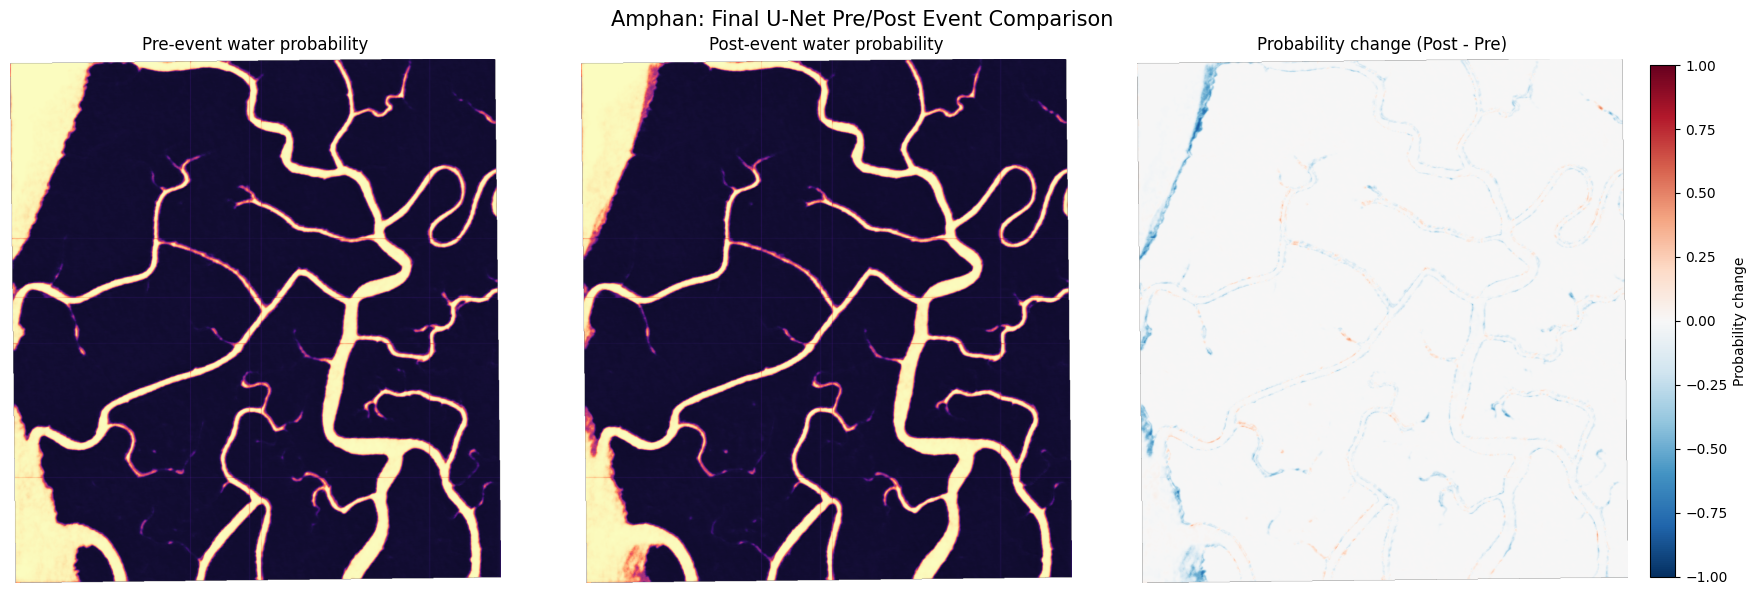


OUTPUT FILES
--------------------------------
/content/drive/MyDrive/Member_A/07_Reproduction_Workspace/results/amphan_final/amphan_pre_probability_final.tif
/content/drive/MyDrive/Member_A/07_Reproduction_Workspace/results/amphan_final/amphan_post_probability_final.tif
/content/drive/MyDrive/Member_A/07_Reproduction_Workspace/results/amphan_final/amphan_pre_prediction_final.tif
/content/drive/MyDrive/Member_A/07_Reproduction_Workspace/results/amphan_final/amphan_post_prediction_final.tif
/content/drive/MyDrive/Member_A/07_Reproduction_Workspace/results/amphan_final/amphan_transition_final.tif
/content/drive/MyDrive/Member_A/07_Reproduction_Workspace/results/amphan_final/amphan_final_comparison.png

FINAL AMPHAN INFERENCE COMPLETED!


In [22]:

# ==========================================================
# MEMBER A: FINAL AMPHAN ZERO-SHOT INFERENCE
# FINAL CLIPPED U-NET CHECKPOINT
# ==========================================================

import torch
import numpy as np
import rasterio
import json
import matplotlib.pyplot as plt

from pathlib import Path


# ==========================================================
# 1. FILE PATHS
# ==========================================================

PRE_PATH = Path(
    "/content/drive/MyDrive/Member_A/07_Reproduction_Workspace/data/amphan_inputs/test_pre_event_s1.tif"
)

POST_PATH = Path(
    "/content/drive/MyDrive/Member_A/07_Reproduction_Workspace/data/amphan_inputs/test_post_event_s1.tif"
)

RESULT_DIR = (
    PROJECT_DIR / "results/amphan_final"
)

RESULT_DIR.mkdir(parents=True, exist_ok=True)

PRE_OUTPUT = RESULT_DIR / "amphan_pre_probability_final.tif"
POST_OUTPUT = RESULT_DIR / "amphan_post_probability_final.tif"

PRE_BINARY_OUTPUT = RESULT_DIR / "amphan_pre_prediction_final.tif"
POST_BINARY_OUTPUT = RESULT_DIR / "amphan_post_prediction_final.tif"

TRANSITION_OUTPUT = RESULT_DIR / "amphan_transition_final.tif"

COMPARISON_OUTPUT = RESULT_DIR / "amphan_final_comparison.png"


# ==========================================================
# 2. LOAD MATCHING PREPROCESSING STATISTICS
# ==========================================================

with open(
    PROJECT_DIR / "data/processed/normalization_stats_clipped.json",
    "r"
) as f:

    stats = json.load(f)

MEAN_FINAL = np.asarray(stats["mean"], dtype=np.float32)
STD_FINAL = np.asarray(stats["std"], dtype=np.float32)

CLIP_MIN_FINAL = np.asarray(
    stats["clip_min"], dtype=np.float32
)

CLIP_MAX_FINAL = np.asarray(
    stats["clip_max"], dtype=np.float32
)


# ==========================================================
# 3. LOAD FINAL BEST CHECKPOINT
# ==========================================================

checkpoint = torch.load(
    FINAL_BEST_PATH,
    map_location=device,
    weights_only=False
)

final_model.load_state_dict(
    checkpoint["model_state_dict"]
)

final_model.eval()

THRESHOLD = float(
    checkpoint["prediction_threshold"]
)

print("FINAL MODEL LOADED")
print("--------------------------------")
print("Best epoch:", checkpoint["epoch"])
print("Best validation IoU:",
      checkpoint["best_validation_iou"])
print("Prediction threshold:", THRESHOLD)


# ==========================================================
# 4. READ AND VALIDATE TIFF FILES
# ==========================================================

def read_sar(path):

    with rasterio.open(path) as src:

        image = src.read().astype(np.float32)

        profile = src.profile.copy()

        transform = src.transform
        crs = src.crs
        nodata = src.nodata

    if image.ndim != 3 or image.shape[0] != 2:
        raise ValueError(
            f"Expected two bands (VV, VH): {path}"
        )

    valid = np.isfinite(image).all(axis=0)

    if nodata is not None and np.isfinite(nodata):

        valid &= np.all(
            image != nodata,
            axis=0
        )

    return image, valid, profile


pre_image, pre_valid, pre_profile = read_sar(PRE_PATH)

post_image, post_valid, post_profile = read_sar(POST_PATH)


# Verify matching grids

if pre_image.shape != post_image.shape:
    raise ValueError("Pre/post dimensions do not match!")

if pre_profile["transform"] != post_profile["transform"]:
    raise ValueError("Pre/post transforms do not match!")

if pre_profile["crs"] != post_profile["crs"]:
    raise ValueError("Pre/post CRS does not match!")

HEIGHT, WIDTH = pre_image.shape[1:]

print("\nAMPHAN IMAGE INFORMATION")
print("--------------------------------")
print("Dimensions:", WIDTH, "x", HEIGHT)
print("CRS:", pre_profile["crs"])
print("Pre valid pixels:", int(pre_valid.sum()))
print("Post valid pixels:", int(post_valid.sum()))

common_valid = pre_valid & post_valid

print("Common valid pixels:", int(common_valid.sum()))


# ==========================================================
# 5. APPLY EXACT TRAINING PREPROCESSING
# ==========================================================

def preprocess_sar(image, valid):

    clipped = np.clip(
        image,
        CLIP_MIN_FINAL[:, None, None],
        CLIP_MAX_FINAL[:, None, None]
    )

    normalized = (
        clipped - MEAN_FINAL[:, None, None]
    ) / STD_FINAL[:, None, None]

    normalized[:, ~valid] = 0.0

    return normalized.astype(np.float32)


pre_normalized = preprocess_sar(
    pre_image, pre_valid
)

post_normalized = preprocess_sar(
    post_image, post_valid
)


# ==========================================================
# 6. SLIDING-WINDOW INFERENCE
# ==========================================================

PATCH_SIZE = 512
STRIDE = 384
INFERENCE_BATCH_SIZE = 4


def get_positions(length):

    if length <= PATCH_SIZE:
        return [0]

    positions = list(
        range(
            0,
            length - PATCH_SIZE + 1,
            STRIDE
        )
    )

    last_position = length - PATCH_SIZE

    if positions[-1] != last_position:
        positions.append(last_position)

    return positions


def predict_large_image(image, valid):

    pad_h = max(0, PATCH_SIZE - image.shape[1])
    pad_w = max(0, PATCH_SIZE - image.shape[2])

    padded = np.pad(
        image,
        ((0, 0), (0, pad_h), (0, pad_w)),
        mode="reflect"
    )

    padded_valid = np.pad(
        valid,
        ((0, pad_h), (0, pad_w)),
        mode="constant",
        constant_values=False
    )

    h, w = padded.shape[1:]

    y_positions = get_positions(h)
    x_positions = get_positions(w)

    coordinates = [
        (y, x)
        for y in y_positions
        for x in x_positions
    ]

    probability_sum = np.zeros(
        (h, w),
        dtype=np.float32
    )

    probability_count = np.zeros(
        (h, w),
        dtype=np.float32
    )

    print("Inference tiles:", len(coordinates))

    with torch.inference_mode():

        for start in range(
            0,
            len(coordinates),
            INFERENCE_BATCH_SIZE
        ):

            batch_coords = coordinates[
                start:start + INFERENCE_BATCH_SIZE
            ]

            patches = np.stack([
                padded[
                    :,
                    y:y + PATCH_SIZE,
                    x:x + PATCH_SIZE
                ]
                for y, x in batch_coords
            ])

            tensor = torch.from_numpy(
                np.ascontiguousarray(patches)
            ).to(device)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                logits = final_model(tensor)

            probabilities = torch.sigmoid(
                logits.float()
            ).cpu().numpy()[:, 0]

            for probability, (y, x) in zip(
                probabilities,
                batch_coords
            ):

                probability_sum[
                    y:y + PATCH_SIZE,
                    x:x + PATCH_SIZE
                ] += probability

                probability_count[
                    y:y + PATCH_SIZE,
                    x:x + PATCH_SIZE
                ] += 1

            print(
                f"Processed {min(start + len(batch_coords), len(coordinates))}"
                f"/{len(coordinates)} tiles",
                end="\r"
            )

    print()

    averaged = probability_sum / np.maximum(
        probability_count, 1
    )

    averaged = averaged[:HEIGHT, :WIDTH]

    averaged[~valid] = np.nan

    return averaged


# ==========================================================
# 7. RUN PRE/POST INFERENCE
# ==========================================================

print("\nRUNNING PRE-EVENT INFERENCE...")

pre_probability = predict_large_image(
    pre_normalized,
    pre_valid
)

print("\nRUNNING POST-EVENT INFERENCE...")

post_probability = predict_large_image(
    post_normalized,
    post_valid
)


# ==========================================================
# 8. GENERATE BINARY PREDICTIONS
# ==========================================================

pre_binary = pre_probability >= THRESHOLD

post_binary = post_probability >= THRESHOLD


# ==========================================================
# 9. SAVE GEOTIFF OUTPUTS
# ==========================================================

def save_single_band(path, array, profile, dtype, nodata):

    output_profile = profile.copy()

    output_profile.update(
        driver="GTiff",
        count=1,
        dtype=dtype,
        nodata=nodata,
        compress="deflate"
    )

    with rasterio.open(
        path,
        "w",
        **output_profile
    ) as dst:

        dst.write(
            array.astype(dtype),
            1
        )


save_single_band(
    PRE_OUTPUT,
    np.where(pre_valid, pre_probability, -9999),
    pre_profile,
    "float32",
    -9999
)

save_single_band(
    POST_OUTPUT,
    np.where(post_valid, post_probability, -9999),
    post_profile,
    "float32",
    -9999
)

save_single_band(
    PRE_BINARY_OUTPUT,
    np.where(pre_valid, pre_binary, 255),
    pre_profile,
    "uint8",
    255
)

save_single_band(
    POST_BINARY_OUTPUT,
    np.where(post_valid, post_binary, 255),
    post_profile,
    "uint8",
    255
)


# ==========================================================
# 10. BINARY TRANSITION ANALYSIS
# ==========================================================

transition = np.full(
    common_valid.shape,
    255,
    dtype=np.uint8
)

# 0 = Persistent non-water
# 1 = Persistent water
# 2 = Newly predicted water
# 3 = Water no longer predicted

persistent_nonwater = (
    ~pre_binary & ~post_binary & common_valid
)

persistent_water = (
    pre_binary & post_binary & common_valid
)

new_water = (
    ~pre_binary & post_binary & common_valid
)

lost_water = (
    pre_binary & ~post_binary & common_valid
)

transition[persistent_nonwater] = 0
transition[persistent_water] = 1
transition[new_water] = 2
transition[lost_water] = 3

save_single_band(
    TRANSITION_OUTPUT,
    transition,
    pre_profile,
    "uint8",
    255
)


# ==========================================================
# 11. AREA CALCULATION
# ==========================================================

transform = pre_profile["transform"]
crs = pre_profile["crs"]

if crs is None or not crs.is_projected:
    raise ValueError(
        "Expected projected CRS for square-metre area calculation."
    )

pixel_area_m2 = abs(
    transform.a * transform.e -
    transform.b * transform.d
)

pixel_area_km2 = pixel_area_m2 / 1e6

total_valid = int(common_valid.sum())

pre_water = int((pre_binary & common_valid).sum())
post_water = int((post_binary & common_valid).sum())

new_count = int(new_water.sum())
lost_count = int(lost_water.sum())

persistent_count = int(persistent_water.sum())
nonwater_count = int(persistent_nonwater.sum())


# ==========================================================
# 12. DISPLAY FINAL RESULTS
# ==========================================================

print("\n========================================")
print("FINAL AMPHAN ZERO-SHOT RESULTS")
print("========================================")

print("Best checkpoint epoch:", checkpoint["epoch"])
print("Threshold:", THRESHOLD)
print("Common valid pixels:", total_valid)

print("\nPREDICTED WATER")

print("Pre-event pixels:", pre_water)
print("Pre-event area:",
      round(pre_water * pixel_area_km2, 4), "km2")

print("Post-event pixels:", post_water)
print("Post-event area:",
      round(post_water * pixel_area_km2, 4), "km2")

print("\nTRANSITIONS")

print("Persistent non-water:", nonwater_count)
print("Persistent water:", persistent_count)

print("Newly predicted water:", new_count)
print("Water no longer predicted:", lost_count)

print("\nAREA CHANGES")

print("New water area:",
      round(new_count * pixel_area_km2, 4), "km2")

print("Lost water area:",
      round(lost_count * pixel_area_km2, 4), "km2")

print("Net predicted water change:",
      round(
          (post_water - pre_water) * pixel_area_km2,
          4
      ), "km2")

print(
    "Jaccard similarity:",
    round(
        persistent_count /
        max(pre_water + post_water - persistent_count, 1),
        5
    )
)


# ==========================================================
# 13. COMPARISON FIGURE
# ==========================================================

change = post_probability - pre_probability

change_display = np.ma.masked_where(
    ~common_valid,
    change
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
)

axes[0].imshow(
    np.ma.masked_where(
        ~common_valid,
        pre_probability
    ),
    cmap="magma",
    vmin=0,
    vmax=1
)

axes[0].set_title("Pre-event water probability")

axes[1].imshow(
    np.ma.masked_where(
        ~common_valid,
        post_probability
    ),
    cmap="magma",
    vmin=0,
    vmax=1
)

axes[1].set_title("Post-event water probability")

im = axes[2].imshow(
    change_display,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

axes[2].set_title("Probability change (Post - Pre)")

for ax in axes:
    ax.axis("off")

fig.colorbar(
    im,
    ax=axes[2],
    fraction=0.046,
    pad=0.04,
    label="Probability change"
)

plt.suptitle(
    "Amphan: Final U-Net Pre/Post Event Comparison",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    COMPARISON_OUTPUT,
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


print("\nOUTPUT FILES")
print("--------------------------------")

print(PRE_OUTPUT)
print(POST_OUTPUT)
print(PRE_BINARY_OUTPUT)
print(POST_BINARY_OUTPUT)
print(TRANSITION_OUTPUT)
print(COMPARISON_OUTPUT)

print("\nFINAL AMPHAN INFERENCE COMPLETED!")


### 6A. Weighted tile blending

RUNNING BLENDED PRE-EVENT INFERENCE...
Processed 9/9 tiles

RUNNING BLENDED POST-EVENT INFERENCE...
Processed 9/9 tiles


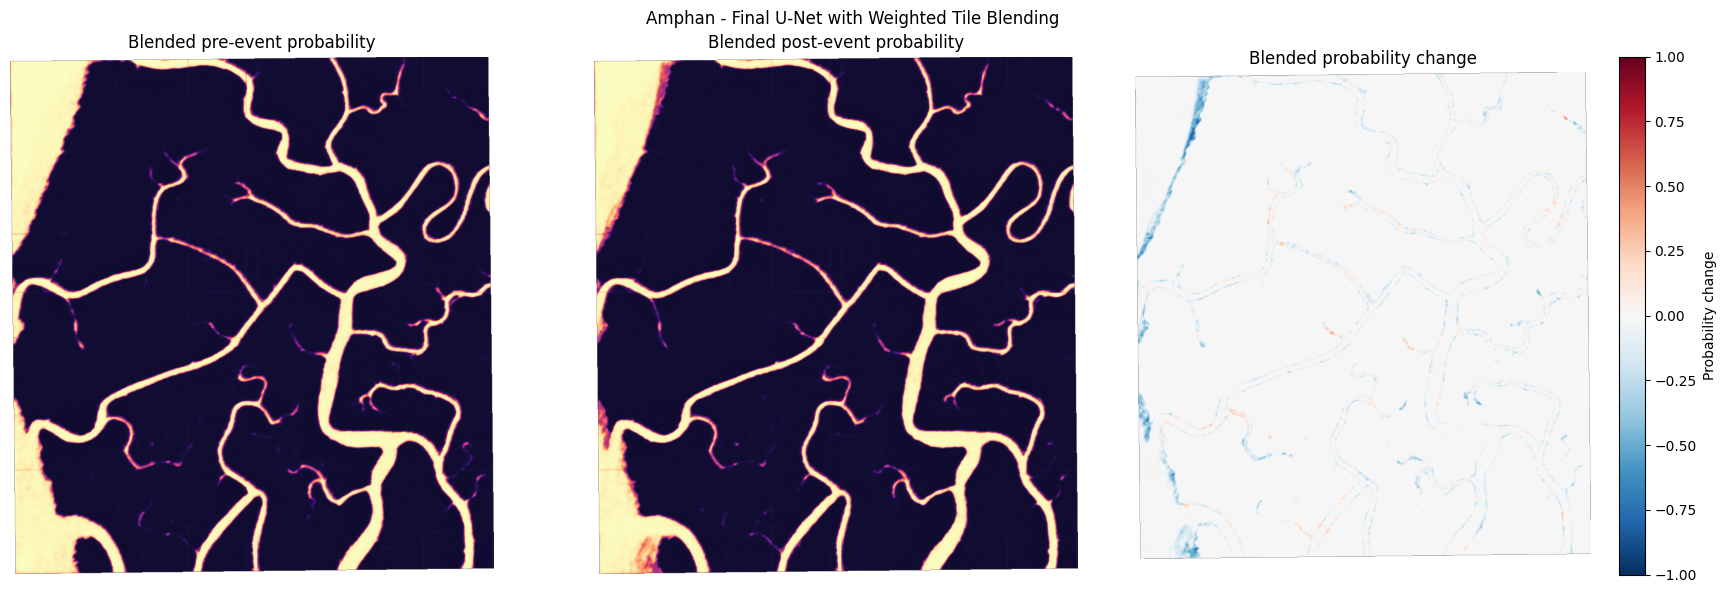


WEIGHTED BLENDED AMPHAN RESULTS
Pre-event predicted water: 18.8736 km2
Post-event predicted water: 17.9362 km2
Persistent water: 17.7785 km2
Newly predicted water: 0.1577 km2
Water no longer predicted: 1.0951 km2
Persistent non-water: 95.6325 km2
Net predicted change: -0.9374 km2
Jaccard similarity: 0.93417

SAVED FILES
/content/drive/MyDrive/Member_A/07_Reproduction_Workspace/results/amphan_final/amphan_pre_probability_blended.tif
/content/drive/MyDrive/Member_A/07_Reproduction_Workspace/results/amphan_final/amphan_post_probability_blended.tif
/content/drive/MyDrive/Member_A/07_Reproduction_Workspace/results/amphan_final/amphan_transition_blended.tif
/content/drive/MyDrive/Member_A/07_Reproduction_Workspace/results/amphan_final/amphan_final_blended_comparison.png

WEIGHTED BLENDING COMPLETED!


In [23]:

# ==========================================================
# MEMBER A: SEAM-REDUCED AMPHAN INFERENCE
# GAUSSIAN-CENTRE-WEIGHTED PATCH BLENDING
# ==========================================================

import numpy as np
import torch
import matplotlib.pyplot as plt
import rasterio
from pathlib import Path


# 1. INFERENCE SETTINGS

PATCH_SIZE = 512
STRIDE = 384
BATCH_SIZE = 4

# Centre-weighted blending window
window_1d = np.hanning(PATCH_SIZE).astype(np.float32)

blend_window = np.outer(
    window_1d,
    window_1d
)

# Avoid zero weights at outer image boundaries
blend_window = np.maximum(
    blend_window,
    0.05
)


# 2. SLIDING-WINDOW POSITION FUNCTION

def get_blend_positions(length):

    if length <= PATCH_SIZE:
        return [0]

    positions = list(
        range(0, length - PATCH_SIZE + 1, STRIDE)
    )

    last = length - PATCH_SIZE

    if positions[-1] != last:
        positions.append(last)

    return positions


# 3. WEIGHTED INFERENCE

def predict_blended(image, valid):

    pad_h = max(0, PATCH_SIZE - image.shape[1])
    pad_w = max(0, PATCH_SIZE - image.shape[2])

    padded = np.pad(
        image,
        ((0, 0), (0, pad_h), (0, pad_w)),
        mode="reflect"
    )

    padded_valid = np.pad(
        valid,
        ((0, pad_h), (0, pad_w)),
        mode="constant",
        constant_values=False
    )

    h, w = padded.shape[1:]

    ys = get_blend_positions(h)
    xs = get_blend_positions(w)

    coordinates = [
        (y, x)
        for y in ys
        for x in xs
    ]

    probability_sum = np.zeros(
        (h, w),
        dtype=np.float32
    )

    weight_sum = np.zeros(
        (h, w),
        dtype=np.float32
    )

    with torch.inference_mode():

        for start in range(
            0,
            len(coordinates),
            BATCH_SIZE
        ):

            batch_coords = coordinates[
                start:start + BATCH_SIZE
            ]

            patches = np.stack([
                padded[
                    :,
                    y:y + PATCH_SIZE,
                    x:x + PATCH_SIZE
                ]
                for y, x in batch_coords
            ])

            tensor = torch.from_numpy(
                np.ascontiguousarray(patches)
            ).to(device)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                logits = final_model(tensor)

            probabilities = torch.sigmoid(
                logits.float()
            ).cpu().numpy()[:, 0]

            for probability, (y, x) in zip(
                probabilities,
                batch_coords
            ):

                probability_sum[
                    y:y + PATCH_SIZE,
                    x:x + PATCH_SIZE
                ] += probability * blend_window

                weight_sum[
                    y:y + PATCH_SIZE,
                    x:x + PATCH_SIZE
                ] += blend_window

            print(
                f"Processed {min(start + BATCH_SIZE, len(coordinates))}"
                f"/{len(coordinates)} tiles",
                end="\r"
            )

    print()

    result = probability_sum / np.maximum(
        weight_sum,
        1e-8
    )

    result = result[:HEIGHT, :WIDTH]

    result[~valid] = np.nan

    return result


# 4. RUN INFERENCE AGAIN

print("RUNNING BLENDED PRE-EVENT INFERENCE...")

pre_probability_blended = predict_blended(
    pre_normalized,
    pre_valid
)

print("\nRUNNING BLENDED POST-EVENT INFERENCE...")

post_probability_blended = predict_blended(
    post_normalized,
    post_valid
)


# 5. BINARY PREDICTIONS AND TRANSITIONS

pre_binary_blended = (
    pre_probability_blended >= THRESHOLD
)

post_binary_blended = (
    post_probability_blended >= THRESHOLD
)

common_valid = pre_valid & post_valid

new_water_blended = (
    ~pre_binary_blended
    & post_binary_blended
    & common_valid
)

lost_water_blended = (
    pre_binary_blended
    & ~post_binary_blended
    & common_valid
)

persistent_water_blended = (
    pre_binary_blended
    & post_binary_blended
    & common_valid
)

persistent_nonwater_blended = (
    ~pre_binary_blended
    & ~post_binary_blended
    & common_valid
)


# 6. SAVE BLENDED GEOTIFF FILES

PRE_BLEND_PATH = RESULT_DIR / "amphan_pre_probability_blended.tif"
POST_BLEND_PATH = RESULT_DIR / "amphan_post_probability_blended.tif"

TRANSITION_BLEND_PATH = RESULT_DIR / "amphan_transition_blended.tif"

save_single_band(
    PRE_BLEND_PATH,
    np.where(pre_valid, pre_probability_blended, -9999),
    pre_profile,
    "float32",
    -9999
)

save_single_band(
    POST_BLEND_PATH,
    np.where(post_valid, post_probability_blended, -9999),
    post_profile,
    "float32",
    -9999
)

transition_blended = np.full(
    common_valid.shape,
    255,
    dtype=np.uint8
)

transition_blended[persistent_nonwater_blended] = 0
transition_blended[persistent_water_blended] = 1
transition_blended[new_water_blended] = 2
transition_blended[lost_water_blended] = 3

save_single_band(
    TRANSITION_BLEND_PATH,
    transition_blended,
    pre_profile,
    "uint8",
    255
)


# 7. RECALCULATE AREA STATISTICS

area_km2 = pixel_area_km2

pre_count = int(
    (pre_binary_blended & common_valid).sum()
)

post_count = int(
    (post_binary_blended & common_valid).sum()
)

persistent_count = int(
    persistent_water_blended.sum()
)

new_count = int(
    new_water_blended.sum()
)

lost_count = int(
    lost_water_blended.sum()
)

nonwater_count = int(
    persistent_nonwater_blended.sum()
)

jaccard = persistent_count / max(
    pre_count + post_count - persistent_count,
    1
)


# 8. DISPLAY BLENDED RESULTS

change_blended = (
    post_probability_blended
    - pre_probability_blended
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
)

axes[0].imshow(
    np.ma.masked_where(
        ~common_valid,
        pre_probability_blended
    ),
    cmap="magma",
    vmin=0,
    vmax=1
)

axes[0].set_title("Blended pre-event probability")

axes[1].imshow(
    np.ma.masked_where(
        ~common_valid,
        post_probability_blended
    ),
    cmap="magma",
    vmin=0,
    vmax=1
)

axes[1].set_title("Blended post-event probability")

im = axes[2].imshow(
    np.ma.masked_where(
        ~common_valid,
        change_blended
    ),
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

axes[2].set_title("Blended probability change")

for ax in axes:
    ax.axis("off")

fig.colorbar(
    im,
    ax=axes[2],
    label="Probability change"
)

plt.suptitle(
    "Amphan - Final U-Net with Weighted Tile Blending"
)

plt.tight_layout()

BLENDED_FIGURE = (
    RESULT_DIR / "amphan_final_blended_comparison.png"
)

plt.savefig(
    BLENDED_FIGURE,
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# 9. PRINT FINAL BLENDED STATISTICS

print("\n==========================================")
print("WEIGHTED BLENDED AMPHAN RESULTS")
print("==========================================")

print("Pre-event predicted water:",
      round(pre_count * area_km2, 4), "km2")

print("Post-event predicted water:",
      round(post_count * area_km2, 4), "km2")

print("Persistent water:",
      round(persistent_count * area_km2, 4), "km2")

print("Newly predicted water:",
      round(new_count * area_km2, 4), "km2")

print("Water no longer predicted:",
      round(lost_count * area_km2, 4), "km2")

print("Persistent non-water:",
      round(nonwater_count * area_km2, 4), "km2")

print("Net predicted change:",
      round((post_count - pre_count) * area_km2, 4), "km2")

print("Jaccard similarity:", round(jaccard, 5))

print("\nSAVED FILES")
print(PRE_BLEND_PATH)
print(POST_BLEND_PATH)
print(TRANSITION_BLEND_PATH)
print(BLENDED_FIGURE)

print("\nWEIGHTED BLENDING COMPLETED!")


### 6B. Transition cluster analysis


FINAL AMPHAN COMPONENT ANALYSIS

NEWLY PREDICTED WATER
--------------------------------
Separate clusters: 691
Largest cluster: 46
Clusters >= 100 pixels: 0
Median cluster size: 1.0

TOP 10 CLUSTERS
             category  component  pixels  area_km2      center_x     center_y  longitude  latitude
NEWLY PREDICTED WATER        233      46    0.0046 678976.521739 2.418900e+06  88.732092 21.865071
NEWLY PREDICTED WATER        366      42    0.0042 681931.190476 2.416506e+06  88.760412 21.843150
NEWLY PREDICTED WATER        358      42    0.0042 681816.666667 2.416650e+06  88.759320 21.844461
NEWLY PREDICTED WATER        352      32    0.0032 680120.000000 2.416854e+06  88.742931 21.846481
NEWLY PREDICTED WATER        629      32    0.0032 685431.562500 2.412619e+06  88.793832 21.807686
NEWLY PREDICTED WATER        465      31    0.0031 677819.193548 2.415059e+06  88.720481 21.830500
NEWLY PREDICTED WATER         18      26    0.0026 685504.615385 2.421778e+06  88.795572 21.890388
NEWLY PR

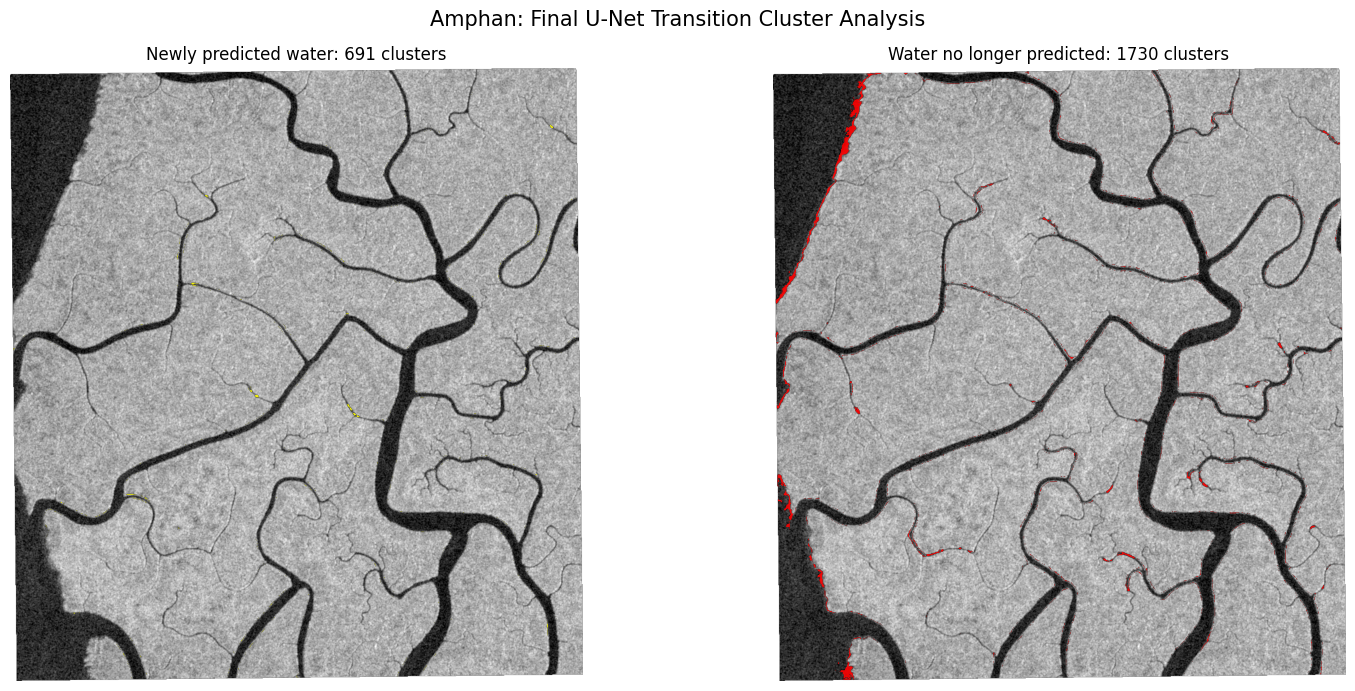


FINAL COMPONENT ANALYSIS SAVED
/content/drive/MyDrive/Member_A/07_Reproduction_Workspace/results/amphan_final/amphan_transition_components_final.csv
/content/drive/MyDrive/Member_A/07_Reproduction_Workspace/results/amphan_final/amphan_transition_clusters_final.png

FINAL AMPHAN CLUSTER ANALYSIS COMPLETED!


In [24]:

# ==========================================================
# MEMBER A: FINAL AMPHAN TRANSITION CLUSTER ANALYSIS
# WEIGHTED BLENDED PREDICTIONS
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import ndimage
from matplotlib.colors import ListedColormap
from pyproj import Transformer


# 1. DEFINE CONNECTIVITY

# 8-connectivity: diagonal neighbours are connected
structure = np.ones((3, 3), dtype=np.uint8)

# Geographic coordinate transformer
transformer = Transformer.from_crs(
    pre_profile["crs"],
    "EPSG:4326",
    always_xy=True
)

affine = pre_profile["transform"]


# 2. COMPONENT ANALYSIS FUNCTION

def analyse_components(mask, category):

    labelled, number = ndimage.label(
        mask.astype(bool),
        structure=structure
    )

    if number == 0:
        print(f"\nNo components found: {category}")
        return [], labelled

    sizes = np.bincount(
        labelled.ravel()
    )

    component_ids = np.arange(1, number + 1)

    counts = sizes[1:]

    centroids = ndimage.center_of_mass(
        mask.astype(np.uint8),
        labelled,
        component_ids
    )

    records = []

    for component, pixels, centroid in zip(
        component_ids,
        counts,
        centroids
    ):

        row, col = centroid

        # Pixel-centre coordinates in projected CRS
        x = (
            affine.c
            + (col + 0.5) * affine.a
            + (row + 0.5) * affine.b
        )

        y = (
            affine.f
            + (col + 0.5) * affine.d
            + (row + 0.5) * affine.e
        )

        lon, lat = transformer.transform(x, y)

        records.append({

            "category": category,
            "component": int(component),
            "pixels": int(pixels),

            "area_km2": float(
                pixels * pixel_area_km2
            ),

            "center_x": float(x),
            "center_y": float(y),

            "longitude": float(lon),
            "latitude": float(lat)

        })

    return records, labelled


# 3. ANALYSE NEWLY PREDICTED WATER

new_records, new_labels = analyse_components(
    new_water_blended,
    "NEWLY PREDICTED WATER"
)


# 4. ANALYSE WATER NO LONGER PREDICTED

lost_records, lost_labels = analyse_components(
    lost_water_blended,
    "WATER NO LONGER PREDICTED"
)


# 5. COMBINE RESULTS

all_records = new_records + lost_records

components_df = pd.DataFrame(all_records)


# 6. SUMMARY REPORT

print("\n==========================================")
print("FINAL AMPHAN COMPONENT ANALYSIS")
print("==========================================")

for category, records in [
    ("NEWLY PREDICTED WATER", new_records),
    ("WATER NO LONGER PREDICTED", lost_records)
]:

    print(f"\n{category}")
    print("--------------------------------")

    if not records:
        print("No clusters.")
        continue

    df = pd.DataFrame(records)

    sizes = df["pixels"]

    print("Separate clusters:", len(df))
    print("Largest cluster:", int(sizes.max()))

    print(
        "Clusters >= 100 pixels:",
        int((sizes >= 100).sum())
    )

    print(
        "Median cluster size:",
        float(sizes.median())
    )

    print("\nTOP 10 CLUSTERS")

    print(
        df.sort_values(
            "pixels",
            ascending=False
        ).head(10).to_string(index=False)
    )


# 7. SAVE CLUSTER CSV

COMPONENT_CSV = (
    RESULT_DIR / "amphan_transition_components_final.csv"
)

components_df.to_csv(
    COMPONENT_CSV,
    index=False
)


# 8. VISUALISE CLUSTERS ON SAR BACKGROUND

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7)
)

sar_background = np.ma.masked_where(
    ~common_valid,
    pre_image[0]
)

for ax in axes:

    ax.imshow(
        sar_background,
        cmap="gray",
        vmin=-25,
        vmax=-2
    )

    ax.axis("off")


# Newly predicted water
new_overlay = np.ma.masked_where(
    ~new_water_blended,
    new_water_blended.astype(float)
)

axes[0].imshow(
    new_overlay,
    cmap=ListedColormap(["yellow"]),
    vmin=0,
    vmax=1,
    alpha=0.9
)

axes[0].set_title(
    f"Newly predicted water: {len(new_records)} clusters"
)


# Water no longer predicted
lost_overlay = np.ma.masked_where(
    ~lost_water_blended,
    lost_water_blended.astype(float)
)

axes[1].imshow(
    lost_overlay,
    cmap=ListedColormap(["red"]),
    vmin=0,
    vmax=1,
    alpha=0.9
)

axes[1].set_title(
    f"Water no longer predicted: {len(lost_records)} clusters"
)


plt.suptitle(
    "Amphan: Final U-Net Transition Cluster Analysis",
    fontsize=15
)

plt.tight_layout()

CLUSTER_FIGURE = (
    RESULT_DIR / "amphan_transition_clusters_final.png"
)

plt.savefig(
    CLUSTER_FIGURE,
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# 9. FINAL OUTPUT

print("\n==========================================")
print("FINAL COMPONENT ANALYSIS SAVED")
print("==========================================")

print(COMPONENT_CSV)
print(CLUSTER_FIGURE)

print("\nFINAL AMPHAN CLUSTER ANALYSIS COMPLETED!")


### 6C. Threshold sensitivity

FINAL AMPHAN THRESHOLD SENSITIVITY
 threshold  pre_water_km2  post_water_km2  new_water_km2  lost_water_km2  net_change_km2  jaccard  new_clusters  lost_clusters
       0.3        20.7534         19.8426         0.2025          1.1133         -0.9108  0.93721           689           1645
       0.4        19.7338         18.8685         0.1760          1.0413         -0.8653  0.93886           692           1648
       0.5        18.8736         17.9362         0.1577          1.0951         -0.9374  0.93417           691           1730
       0.6        18.0444         17.0144         0.1441          1.1741         -1.0300  0.92753           687           1636
       0.7        17.2371         16.1474         0.1441          1.2338         -1.0897  0.92072           658           1588


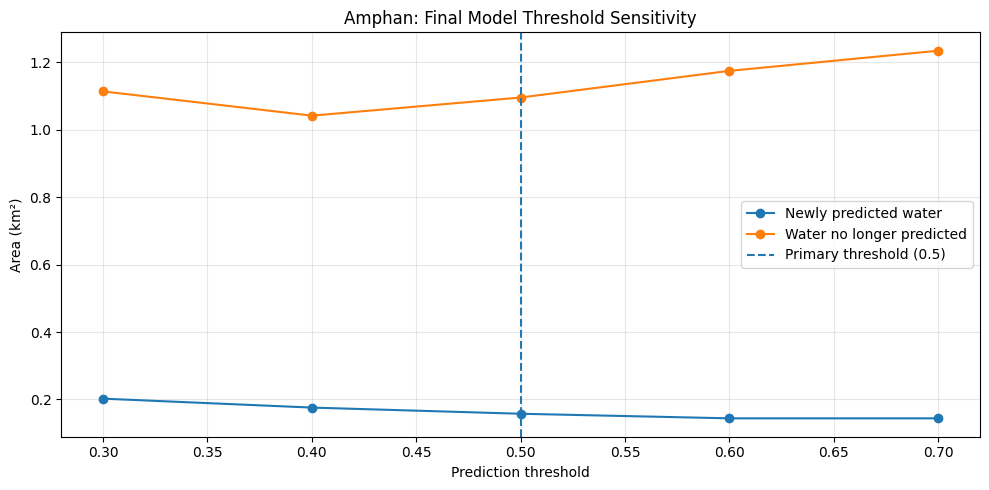

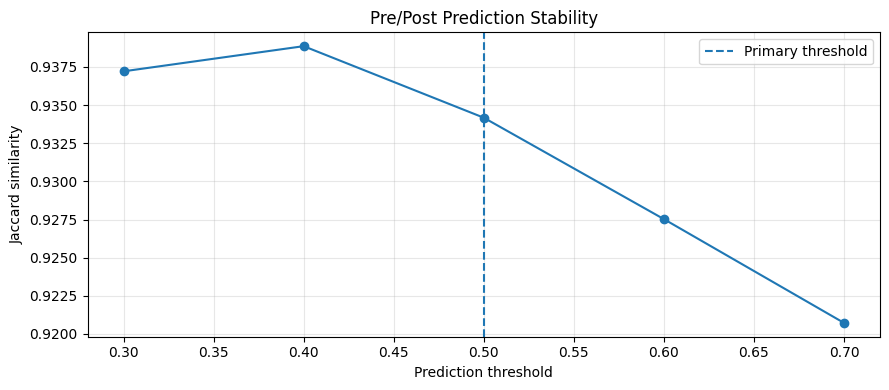


THRESHOLD SENSITIVITY COMPLETED!
Primary threshold: 0.5
CSV: /content/drive/MyDrive/Member_A/07_Reproduction_Workspace/results/amphan_final/amphan_threshold_sensitivity_final.csv
Area graph: /content/drive/MyDrive/Member_A/07_Reproduction_Workspace/results/amphan_final/amphan_threshold_sensitivity_final.png
Jaccard graph: /content/drive/MyDrive/Member_A/07_Reproduction_Workspace/results/amphan_final/amphan_jaccard_sensitivity_final.png


In [25]:

# ==========================================================
# MEMBER A: FINAL AMPHAN THRESHOLD SENSITIVITY
# WEIGHTED BLENDED PROBABILITIES
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import ndimage


# 1. THRESHOLDS

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

structure = np.ones((3, 3), dtype=np.uint8)

records = []


# 2. EVALUATE EACH THRESHOLD

for threshold in thresholds:

    pre_binary = (
        (pre_probability_blended >= threshold)
        & common_valid
    )

    post_binary = (
        (post_probability_blended >= threshold)
        & common_valid
    )

    # Transition classes
    persistent_water = (
        pre_binary & post_binary
    )

    new_water = (
        ~pre_binary & post_binary & common_valid
    )

    lost_water = (
        pre_binary & ~post_binary & common_valid
    )

    # Pixel counts
    pre_count = int(pre_binary.sum())
    post_count = int(post_binary.sum())

    persistent_count = int(persistent_water.sum())
    new_count = int(new_water.sum())
    lost_count = int(lost_water.sum())

    # Jaccard similarity
    union = pre_count + post_count - persistent_count

    jaccard = persistent_count / max(union, 1)

    # Connected components
    _, new_clusters = ndimage.label(
        new_water,
        structure=structure
    )

    _, lost_clusters = ndimage.label(
        lost_water,
        structure=structure
    )

    records.append({

        "threshold": threshold,

        "pre_water_km2":
            pre_count * pixel_area_km2,

        "post_water_km2":
            post_count * pixel_area_km2,

        "new_water_km2":
            new_count * pixel_area_km2,

        "lost_water_km2":
            lost_count * pixel_area_km2,

        "net_change_km2":
            (post_count - pre_count) * pixel_area_km2,

        "jaccard": jaccard,

        "new_clusters": new_clusters,

        "lost_clusters": lost_clusters

    })


# 3. CREATE DATAFRAME

sensitivity_df = pd.DataFrame(records)

print("FINAL AMPHAN THRESHOLD SENSITIVITY")
print("==========================================")

print(
    sensitivity_df.round(5).to_string(index=False)
)


# 4. SAVE CSV

SENSITIVITY_CSV = (
    RESULT_DIR / "amphan_threshold_sensitivity_final.csv"
)

sensitivity_df.to_csv(
    SENSITIVITY_CSV,
    index=False
)


# 5. PLOT AREA CHANGES

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    sensitivity_df["threshold"],
    sensitivity_df["new_water_km2"],
    marker="o",
    label="Newly predicted water"
)

ax.plot(
    sensitivity_df["threshold"],
    sensitivity_df["lost_water_km2"],
    marker="o",
    label="Water no longer predicted"
)

ax.axvline(
    0.5,
    linestyle="--",
    label="Primary threshold (0.5)"
)

ax.set_xlabel("Prediction threshold")
ax.set_ylabel("Area (km²)")

ax.set_title(
    "Amphan: Final Model Threshold Sensitivity"
)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

SENSITIVITY_PNG = (
    RESULT_DIR / "amphan_threshold_sensitivity_final.png"
)

plt.savefig(
    SENSITIVITY_PNG,
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# 6. PLOT JACCARD STABILITY

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(
    sensitivity_df["threshold"],
    sensitivity_df["jaccard"],
    marker="o"
)

ax.axvline(
    0.5,
    linestyle="--",
    label="Primary threshold"
)

ax.set_xlabel("Prediction threshold")
ax.set_ylabel("Jaccard similarity")

ax.set_title(
    "Pre/Post Prediction Stability"
)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

JACCARD_PNG = (
    RESULT_DIR / "amphan_jaccard_sensitivity_final.png"
)

plt.savefig(
    JACCARD_PNG,
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# 7. FINAL SUMMARY

print("\n==========================================")
print("THRESHOLD SENSITIVITY COMPLETED!")
print("==========================================")

print("Primary threshold: 0.5")

print("CSV:", SENSITIVITY_CSV)
print("Area graph:", SENSITIVITY_PNG)
print("Jaccard graph:", JACCARD_PNG)


In [26]:

print(
    sensitivity_df.round(5).to_string(index=False)
)


 threshold  pre_water_km2  post_water_km2  new_water_km2  lost_water_km2  net_change_km2  jaccard  new_clusters  lost_clusters
       0.3        20.7534         19.8426         0.2025          1.1133         -0.9108  0.93721           689           1645
       0.4        19.7338         18.8685         0.1760          1.0413         -0.8653  0.93886           692           1648
       0.5        18.8736         17.9362         0.1577          1.0951         -0.9374  0.93417           691           1730
       0.6        18.0444         17.0144         0.1441          1.1741         -1.0300  0.92753           687           1636
       0.7        17.2371         16.1474         0.1441          1.2338         -1.0897  0.92072           658           1588


## 7. Final artifact audit

In [27]:

# ==========================================================
# MEMBER A: FINAL EXPERIMENT ARTIFACT AUDIT
# ==========================================================

from pathlib import Path
import pandas as pd
import json

ROOT = Path(
    "/content/drive/MyDrive/Member_A/07_Reproduction_Workspace"
)

# 1. IMPORTANT FINAL ARTIFACTS

artifacts = {

    "Final best U-Net checkpoint":
        ROOT / "checkpoints/best_unet_resnet34_final_iou.pth",

    "Latest U-Net checkpoint":
        ROOT / "checkpoints/latest_unet_resnet34_final_iou.pth",

    "Final training history":
        ROOT / "logs/training_history_final_iou.csv",

    "Clipped normalization statistics":
        ROOT / "data/processed/normalization_stats_clipped.json",

    "Global test metrics":
        ROOT / "logs/global_test_metrics_final_iou.json",

    "Per-image test metrics":
        ROOT / "logs/per_image_test_metrics_final_iou.csv",

    "Worst positive image visualisation":
        ROOT / "logs/worst_positive_visuals_final.png",

    "Water-negative visualisation":
        ROOT / "logs/water_negative_visuals_final.png",

    "Amphan pre-event probability":
        ROOT / "results/amphan_final/amphan_pre_probability_blended.tif",

    "Amphan post-event probability":
        ROOT / "results/amphan_final/amphan_post_probability_blended.tif",

    "Amphan transition GeoTIFF":
        ROOT / "results/amphan_final/amphan_transition_blended.tif",

    "Amphan final comparison":
        ROOT / "results/amphan_final/amphan_final_blended_comparison.png",

    "Amphan transition components":
        ROOT / "results/amphan_final/amphan_transition_components_final.csv",

    "Amphan cluster visualisation":
        ROOT / "results/amphan_final/amphan_transition_clusters_final.png",

    "Threshold sensitivity CSV":
        ROOT / "results/amphan_final/amphan_threshold_sensitivity_final.csv",

    "Threshold sensitivity graph":
        ROOT / "results/amphan_final/amphan_threshold_sensitivity_final.png",

    "Jaccard sensitivity graph":
        ROOT / "results/amphan_final/amphan_jaccard_sensitivity_final.png"

}


# 2. CHECK EXISTENCE AND FILE SIZES

records = []

for name, path in artifacts.items():

    exists = path.is_file()

    size_mb = (
        round(path.stat().st_size / (1024 ** 2), 3)
        if exists else None
    )

    records.append({

        "Artifact": name,
        "Status": "AVAILABLE" if exists else "MISSING",
        "Size_MB": size_mb,
        "Path": str(path)

    })


manifest = pd.DataFrame(records)


# 3. SAVE MANIFEST

MANIFEST_PATH = ROOT / "member_a_final_artifact_manifest.csv"

manifest.to_csv(
    MANIFEST_PATH,
    index=False
)


# 4. DISPLAY RESULTS

print("MEMBER A FINAL ARTIFACT AUDIT")
print("==========================================")

print(manifest[
    ["Artifact", "Status", "Size_MB"]
].to_string(index=False))

available = sum(
    record["Status"] == "AVAILABLE"
    for record in records
)

missing = len(records) - available

print("\n==========================================")
print("TOTAL ARTIFACTS:", len(records))
print("AVAILABLE:", available)
print("MISSING:", missing)

print("\nMANIFEST SAVED:")
print(MANIFEST_PATH)

if missing == 0:
    print("\nALL FINAL ARTIFACTS VERIFIED!")
else:
    print("\nPLEASE CHECK THE MISSING ARTIFACTS.")


MEMBER A FINAL ARTIFACT AUDIT
                          Artifact    Status  Size_MB
       Final best U-Net checkpoint AVAILABLE  279.910
           Latest U-Net checkpoint AVAILABLE  279.915
            Final training history AVAILABLE    0.004
  Clipped normalization statistics AVAILABLE    0.000
               Global test metrics AVAILABLE    0.001
            Per-image test metrics AVAILABLE    0.014
Worst positive image visualisation AVAILABLE    3.876
      Water-negative visualisation AVAILABLE    2.887
      Amphan pre-event probability AVAILABLE    3.682
     Amphan post-event probability AVAILABLE    3.688
         Amphan transition GeoTIFF AVAILABLE    0.023
           Amphan final comparison AVAILABLE    1.886
      Amphan transition components AVAILABLE    0.225
      Amphan cluster visualisation AVAILABLE    1.481
         Threshold sensitivity CSV AVAILABLE    0.001
       Threshold sensitivity graph AVAILABLE    0.072
         Jaccard sensitivity graph AVAILABLE    0.07

In [28]:

from pathlib import Path

# Main Member A folder in Google Drive
member_a_root = Path("/content/drive/MyDrive/Member_A")

# Verify that the final artifact audit exists
manifest = (
    member_a_root
    / "07_Reproduction_Workspace"
    / "member_a_final_artifact_manifest.csv"
)

assert member_a_root.exists(), "Member_A folder not found!"
assert manifest.exists(), "Final artifact manifest not found!"

readme_content = r"""
# Member A — Cross-Event Flood Mapping

## 1. Project Overview

This contribution implements a reproducible workflow for SAR-based
flood mapping and cross-event water-change analysis.

The workflow includes dataset preparation, model restoration,
unseen test evaluation, Amphan pre/post-event inference,
transition analysis, and threshold sensitivity analysis.

## 2. Model Architecture

- Architecture: U-Net
- Encoder: ResNet34
- Input channels: 2 (SAR VV and VH)
- Output channels: 1 (binary segmentation)
- Best checkpoint epoch: 22
- Best validation IoU: 0.638658
- Prediction threshold: 0.5

The saved checkpoint is restored for evaluation and inference.

## 3. Dataset and Preprocessing

Dataset split sizes:

| Split | Images |
|---|---:|
| Training | 251 |
| Validation | 86 |
| Testing | 88 |

Preprocessing includes clipped normalization, no-data masking,
and training augmentation with random crops, flips and rotations.

## 4. Unseen Test Evaluation

Global test metrics:

| Metric | Result |
|---|---:|
| IoU | 0.63605 |
| Dice | 0.77755 |
| Precision | 0.79409 |
| Recall | 0.76168 |
| Accuracy | 0.94638 |
| Specificity | 0.97229 |
| Macro positive-image IoU | 0.41107 |

Evaluation was performed on 88 unseen test images.

## 5. Amphan Zero-Shot Flood Mapping

Input image information:

- Dimensions: 1047 × 1120
- CRS: EPSG:32645
- Common valid pixels: 1,146,638
- Prediction threshold: 0.5

Weighted blended inference results:

| Measurement | Result |
|---|---:|
| Pre-event predicted water | 18.8736 km² |
| Post-event predicted water | 17.9362 km² |
| Persistent water | 17.7785 km² |
| Newly predicted water | 0.1577 km² |
| Water no longer predicted | 1.0951 km² |
| Net predicted water change | -0.9374 km² |
| Jaccard similarity | 0.93417 |

These values represent model predictions, not independently
verified measurements of actual flood-area change.

## 6. Transition Cluster Analysis

Newly predicted water:
- Number of clusters: 691
- Largest cluster: 46 pixels
- Clusters with at least 100 pixels: 0

Water no longer predicted:
- Number of clusters: 1730
- Largest cluster: 2665 pixels
- Clusters with at least 100 pixels: 8

## 7. Threshold Sensitivity

Thresholds evaluated: 0.3, 0.4, 0.5, 0.6 and 0.7.

The highest pre/post map Jaccard similarity was 0.93886 at
threshold 0.4.

The primary prediction threshold remains 0.5, as stored
in the selected checkpoint.

Map Jaccard similarity measures overlap between the two
predicted maps; it is not ground-truth segmentation accuracy.

## 8. Project Structure

Member_A/
- 01_Notebooks/
  - Member_A_Reproducible_Ready.ipynb
- 07_Reproduction_Workspace/
  - checkpoints/
  - data/
  - logs/
  - results/
  - member_a_final_artifact_manifest.csv
- README.md

## 9. Reproduction Instructions

1. Open Member_A_Reproducible_Ready.ipynb in Google Colab.
2. Mount Google Drive.
3. Confirm the project directory points to:
   /content/drive/MyDrive/Member_A/07_Reproduction_Workspace
4. Install the notebook's required dependencies.
   The verified environment used segmentation-models-pytorch 0.6.0.
5. Execute the notebook sections in order.
6. Restore the saved checkpoint before evaluation and inference.
7. Run the Amphan inference and subsequent analysis sections.
8. Run the final artifact audit to verify generated outputs.

Use the saved checkpoint for reproduction; model retraining
is not required for the evaluation and inference workflow.

## 10. Artifact Verification

Final artifact audit:

- Expected artifacts: 17
- Available artifacts: 17
- Missing artifacts: 0

Manifest:
07_Reproduction_Workspace/member_a_final_artifact_manifest.csv

All 17 expected artifacts were verified in the final audit.
"""

readme_path = member_a_root / "README.md"
readme_path.write_text(readme_content.strip() + "\n", encoding="utf-8")

print("README CREATED SUCCESSFULLY")
print("Location:", readme_path)
print("Size:", round(readme_path.stat().st_size / 1024, 2), "KB")


README CREATED SUCCESSFULLY
Location: /content/drive/MyDrive/Member_A/README.md
Size: 3.61 KB
